# Solver de cubo mágico 3×3

## Preparação e funções

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [14]:
def print_cubo(cubo):
    c = np.array(cubo, dtype=str)

    U = c[0:9].reshape(3, 3)
    L = c[9:18].reshape(3, 3)
    F = c[18:27].reshape(3, 3)
    R = c[27:36].reshape(3, 3)
    B = c[36:45].reshape(3, 3)
    D = c[45:54].reshape(3, 3)

    espaço = "       "

    for i in range(3):
        print(f"{espaço}{U[i,0]} {U[i,1]} {U[i,2]}")

    print()

    for i in range(3):
        linha_L = f"{L[i,0]} {L[i,1]} {L[i,2]}"
        linha_F = f"{F[i,0]} {F[i,1]} {F[i,2]}"
        linha_R = f"{R[i,0]} {R[i,1]} {R[i,2]}"
        linha_B = f"{B[i,0]} {B[i,1]} {B[i,2]}"
        print(f"{linha_L}  {linha_F}  {linha_R}  {linha_B}")

    print()

    for i in range(3):
        print(f"{espaço}{D[i,0]} {D[i,1]} {D[i,2]}")

def plotar_cubo(cubo):
    cubo = np.asarray(cubo)
    quadrados = []
    cores = []

    for inicio, grade, direcao_linha, direcao_coluna, normal in faces_3d:
        v_linha = np.array(direcao_linha, dtype=float)
        v_coluna = np.array(direcao_coluna, dtype=float)
        n = np.array(normal, dtype=float)

        for linha in range(3):
            for coluna in range(3):
                centro = grade[linha, coluna].astype(float) + 0.015 * n
                cantos = [
                    centro - 0.4*v_linha - 0.4*v_coluna,
                    centro - 0.4*v_linha + 0.4*v_coluna,
                    centro + 0.4*v_linha + 0.4*v_coluna,
                    centro + 0.4*v_linha - 0.4*v_coluna,
                ]
                quadrados.append(cantos)
                cores.append(cores_plot[str(cubo[inicio + 3*linha + coluna])])

    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection="3d")
    adesivos = Poly3DCollection(
        quadrados, facecolors=cores, edgecolors="black", linewidths=1.5
    )
    ax.add_collection3d(adesivos)
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), zlim=(-1.6, 1.6),
           xlabel="x: frente/trás", ylabel="y: esquerda/direita",
           zlabel="z: baixo/cima")
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=24, azim=-55)
    plt.show()


def girar_cubo(cubo, mapa_de_permutacao):
    return cubo[mapa_de_permutacao]


## Estado do cubo: vetor de 54 adesivos

Criação do estado resolvido e inspeção da ordem das faces `[U, L, F, R, B, D]`.


In [15]:
# Construindo o cubo magico
possiveis_cores = ['W','G','R','B','O','Y']
cubo_resolvido = np.repeat(possiveis_cores, 9)
print(cubo_resolvido)
print_cubo(cubo_resolvido)
print('\n\n')

cubo_teste = np.arange(54)
print_cubo(cubo_teste)
print('\n\n')

for face, inicio in zip("ULFRBD", range(0, 54, 9)):
    print(face, cubo_resolvido[inicio:inicio + 9])


['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G'
 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B'
 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']
       W W W
       W W W
       W W W

G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y



       0 1 2
       3 4 5
       6 7 8

9 10 11  18 19 20  27 28 29  36 37 38
12 13 14  21 22 23  30 31 32  39 40 41
15 16 17  24 25 26  33 34 35  42 43 44

       45 46 47
       48 49 50
       51 52 53



U ['W' 'W' 'W' 'W' 'W' 'W' 'W' 'W' 'W']
L ['G' 'G' 'G' 'G' 'G' 'G' 'G' 'G' 'G']
F ['R' 'R' 'R' 'R' 'R' 'R' 'R' 'R' 'R']
R ['B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B']
B ['O' 'O' 'O' 'O' 'O' 'O' 'O' 'O' 'O']
D ['Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']


## Primeiro experimento: movimento U manual

Este bloco preserva o mapa escrito manualmente e o teste de aplicar U quatro vezes.


In [16]:
movimento_U = np.arange(54)
movimento_U[9], movimento_U[10], movimento_U[11] = 18, 19, 20
movimento_U[18], movimento_U[19], movimento_U[20] = 27, 28, 29
movimento_U[27], movimento_U[28], movimento_U[29] = 36, 37, 38
movimento_U[36], movimento_U[37], movimento_U[38] = 9,10,11
movimento_U[0], movimento_U[1], movimento_U[2] = 6, 3, 0
movimento_U[3], movimento_U[4], movimento_U[5] = 7, 4, 1
movimento_U[6], movimento_U[7], movimento_U[8] = 8, 5, 2

cubo_atual = cubo_resolvido.copy()
for i in range(1, 5):
    cubo_atual = girar_cubo(cubo_atual, movimento_U)
    print(f"--- Giro {i} ---")
    print_cubo(cubo_atual)

--- Giro 1 ---
       W W W
       W W W
       W W W

R R R  B B B  O O O  G G G
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 2 ---
       W W W
       W W W
       W W W

B B B  O O O  G G G  R R R
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 3 ---
       W W W
       W W W
       W W W

O O O  G G G  R R R  B B B
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y
--- Giro 4 ---
       W W W
       W W W
       W W W

G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y


## Coordenadas das faces em R³

Experimentos com as coordenadas e rotações das faces U e F, seguidos das coordenadas das outras faces.


In [17]:
coordenadas_U = np.zeros((3, 3, 3), dtype=int)
for linha in range(3):
    for coluna in range(3):
        coordenadas_U[linha, coluna] = (linha - 1, 1 - coluna, 1)

move_U = np.array([
    [0,  1, 0],
    [-1, 0, 0],
    [0,  0, 1]
])

coordenadas_U_giradas = coordenadas_U @ move_U.T
print(coordenadas_U)
print("Após U:")
print(coordenadas_U_giradas)


[[[-1  1  1]
  [-1  0  1]
  [-1 -1  1]]

 [[ 0  1  1]
  [ 0  0  1]
  [ 0 -1  1]]

 [[ 1  1  1]
  [ 1  0  1]
  [ 1 -1  1]]]
Após U:
[[[ 1  1  1]
  [ 0  1  1]
  [-1  1  1]]

 [[ 1  0  1]
  [ 0  0  1]
  [-1  0  1]]

 [[ 1 -1  1]
  [ 0 -1  1]
  [-1 -1  1]]]


In [18]:
coordenadas_F = np.zeros((3, 3, 3), dtype=int)
for linha in range(3):
    for coluna in range(3):
        coordenadas_F[linha, coluna] = (1, 1 - coluna, 1 - linha)

move_U_front = np.array([
    [1,  0,  0],
    [0,  0,  1],
    [0, -1,  0]
])

coordenadas_F_giradas = coordenadas_F @ move_U_front.T
print(coordenadas_F)
print("Após F:")
print(coordenadas_F_giradas)


[[[ 1  1  1]
  [ 1  0  1]
  [ 1 -1  1]]

 [[ 1  1  0]
  [ 1  0  0]
  [ 1 -1  0]]

 [[ 1  1 -1]
  [ 1  0 -1]
  [ 1 -1 -1]]]
Após F:
[[[ 1  1 -1]
  [ 1  1  0]
  [ 1  1  1]]

 [[ 1  0 -1]
  [ 1  0  0]
  [ 1  0  1]]

 [[ 1 -1 -1]
  [ 1 -1  0]
  [ 1 -1  1]]]


In [19]:
# A ordem das faces continua sendo [U, L, F, R, B, D].

coordenadas_L = np.zeros((3, 3, 3), dtype=int)
coordenadas_R = np.zeros((3, 3, 3), dtype=int)
coordenadas_B = np.zeros((3, 3, 3), dtype=int)
coordenadas_D = np.zeros((3, 3, 3), dtype=int)

for linha in range(3):
    for coluna in range(3):
        coordenadas_L[linha, coluna] = (coluna - 1, 1, 1 - linha)
        coordenadas_R[linha, coluna] = (1 - coluna, -1, 1 - linha)
        coordenadas_B[linha, coluna] = (-1, coluna - 1, 1 - linha)
        coordenadas_D[linha, coluna] = (1 - linha, 1 - coluna, -1)

print("L:\n", coordenadas_L)
print("R:\n", coordenadas_R)
print("B:\n", coordenadas_B)
print("D:\n", coordenadas_D)

L:
 [[[-1  1  1]
  [ 0  1  1]
  [ 1  1  1]]

 [[-1  1  0]
  [ 0  1  0]
  [ 1  1  0]]

 [[-1  1 -1]
  [ 0  1 -1]
  [ 1  1 -1]]]
R:
 [[[ 1 -1  1]
  [ 0 -1  1]
  [-1 -1  1]]

 [[ 1 -1  0]
  [ 0 -1  0]
  [-1 -1  0]]

 [[ 1 -1 -1]
  [ 0 -1 -1]
  [-1 -1 -1]]]
B:
 [[[-1 -1  1]
  [-1  0  1]
  [-1  1  1]]

 [[-1 -1  0]
  [-1  0  0]
  [-1  1  0]]

 [[-1 -1 -1]
  [-1  0 -1]
  [-1  1 -1]]]
D:
 [[[ 1  1 -1]
  [ 1  0 -1]
  [ 1 -1 -1]]

 [[ 0  1 -1]
  [ 0  0 -1]
  [ 0 -1 -1]]

 [[-1  1 -1]
  [-1  0 -1]
  [-1 -1 -1]]]


## Geometria completa e plot do cubo

Agrupamento das seis grades, direções e normais usadas para desenhar o cubo.


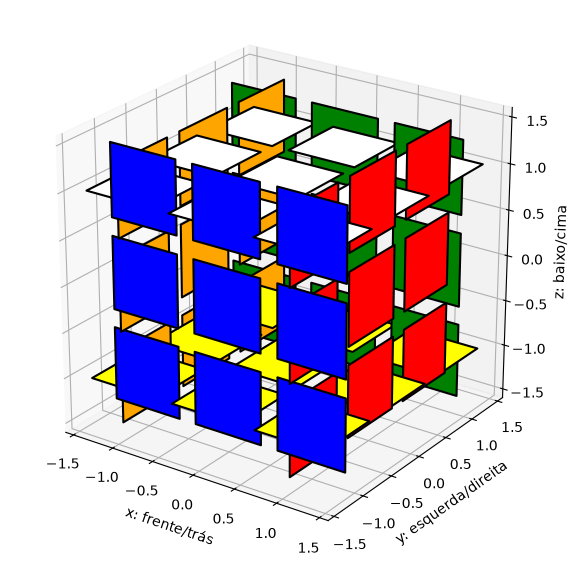

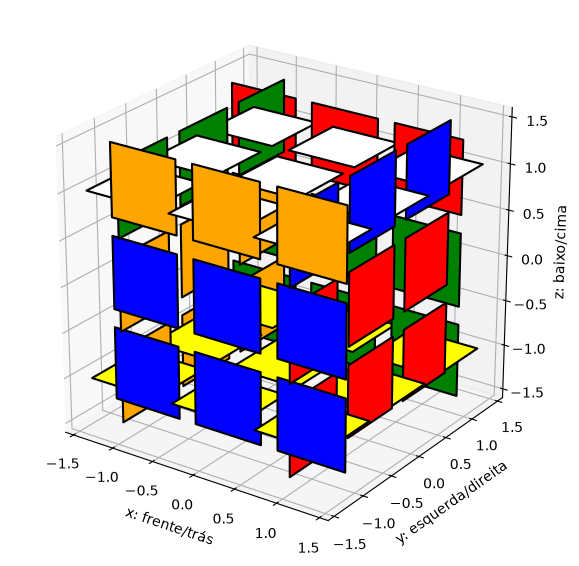

In [20]:
faces_3d = [
    (0,  coordenadas_U, (1, 0, 0),  (0, -1, 0), (0, 0, 1)),   # U: cima (+z)
    (9,  coordenadas_L, (0, 0, -1), (1, 0, 0),  (0, 1, 0)),   # L: esquerda (+y)
    (18, coordenadas_F, (0, 0, -1), (0, -1, 0), (1, 0, 0)),   # F: frente (+x)
    (27, coordenadas_R, (0, 0, -1), (-1, 0, 0), (0, -1, 0)),  # R: direita (-y)
    (36, coordenadas_B, (0, 0, -1), (0, 1, 0),  (-1, 0, 0)), # B: trás (-x)
    (45, coordenadas_D, (-1, 0, 0), (0, -1, 0), (0, 0, -1)), # D: baixo (-z)
]

cores_plot = {
    "W": "white",
    "G": "green",
    "R": "red",
    "B": "blue",
    "O": "orange",
    "Y": "yellow",
}

plotar_cubo(cubo_resolvido)
plotar_cubo(girar_cubo(cubo_resolvido, movimento_U))

## Gerar movimentos a partir da geometria

A função abaixo recebe o nome da face e constrói o mapa de permutação correspondente.


In [21]:
def gerar_mapa_movimento(nome_face):
    """
    Gera um mapa para usar como cubo_novo = cubo[mapa].

    nome_face escolhe a camada e define o sentido horário visto de fora.
    """
    inicio_por_face = {"U": 0, "L": 9, "F": 18,
                       "R": 27, "B": 36, "D": 45}
    inicio_alvo = inicio_por_face[nome_face.upper()]
    face_alvo = next(face for face in faces_3d if face[0] == inicio_alvo)
    _, _, direcao_linha, direcao_coluna, normal_camada = face_alvo

    # Coordenadas locais: linha, coluna, normal. A rotação gira
    # a grade 90 graus no sentido horário quando vista de fora da face.
    base = np.column_stack((direcao_linha, direcao_coluna, normal_camada))
    giro_local = np.array([[0, 1, 0], [-1, 0, 0], [0, 0, 1]])
    matriz_rotacao = base @ giro_local @ base.T
    n_camada = np.array(normal_camada, dtype=int)
    # Relaciona cada posição e orientação de adesivo ao índice no vetor.
    indice_por_geometria = {}

    for inicio, grade, direcao_linha, direcao_coluna, normal in faces_3d:
        normal_adesivo = tuple(normal)

        for linha in range(3):
            for coluna in range(3):
                indice = inicio + 3 * linha + coluna
                posicao = tuple(int(x) for x in grade[linha, coluna])
                indice_por_geometria[(posicao, normal_adesivo)] = indice

    mapa = np.empty(54, dtype=int)

    for inicio, grade, direcao_linha, direcao_coluna, normal in faces_3d:
        n_adesivo = np.array(normal, dtype=int)

        for linha in range(3):
            for coluna in range(3):
                origem = inicio + 3 * linha + coluna
                posicao = np.array(grade[linha, coluna], dtype=int)

                # O produto escalar igual a 1 seleciona a camada externa.
                if np.dot(posicao, n_camada) == 1:
                    nova_posicao = matriz_rotacao @ posicao
                    nova_normal = matriz_rotacao @ n_adesivo
                else:
                    nova_posicao = posicao
                    nova_normal = n_adesivo

                chave_destino = (
                    tuple(int(x) for x in nova_posicao),
                    tuple(int(x) for x in nova_normal),
                )
                destino = indice_por_geometria[chave_destino]

                # girar_cubo usa cubo[mapa]:
                # em cada destino, guardamos o índice de origem.
                mapa[destino] = origem

    return mapa

## Aplicar e explorar os movimentos gerados

Experimentos atuais com U, F e F². Os códigos e testes existentes foram mantidos.


       W W W
       W W W
       W W W

R R R  B B B  O O O  G G G
G G G  R R R  B B B  O O O
G G G  R R R  B B B  O O O

       Y Y Y
       Y Y Y
       Y Y Y


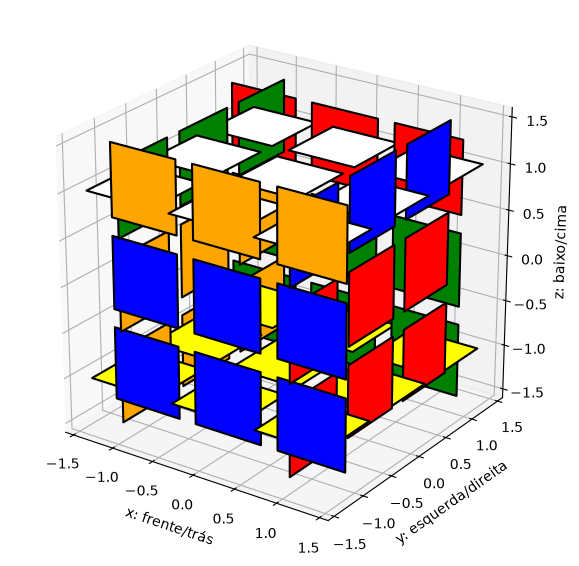

       W W W
       W W W
       G G G

G G Y  R R R  W B B  O O O
G G Y  R R R  W B B  O O O
G G Y  R R R  W B B  O O O

       B B B
       Y Y Y
       Y Y Y


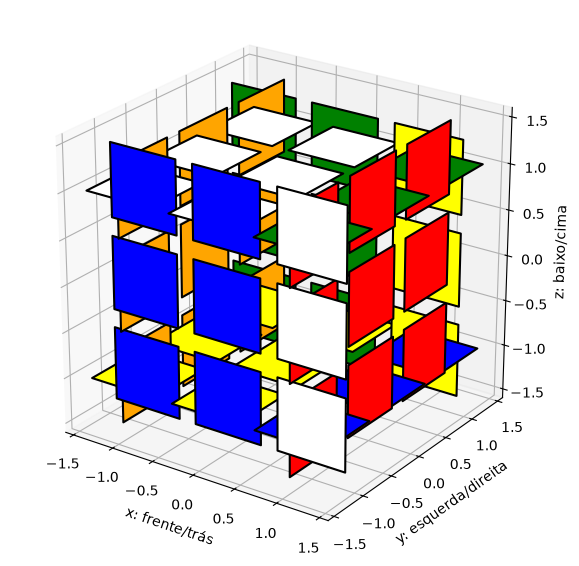

       W W W
       W W W
       Y Y Y

G G B  R R R  G B B  O O O
G G B  R R R  G B B  O O O
G G B  R R R  G B B  O O O

       W W W
       Y Y Y
       Y Y Y


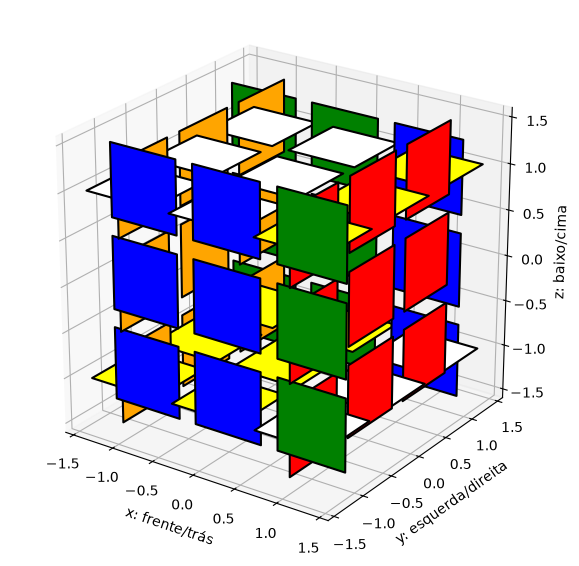

In [22]:
mapa_U_geometrico = gerar_mapa_movimento("U")

cubo_depois_de_U = girar_cubo(cubo_resolvido, mapa_U_geometrico)

print_cubo(cubo_depois_de_U)
plotar_cubo(cubo_depois_de_U)

mapa_F_geometrico = gerar_mapa_movimento("F")

cubo_depois_de_F = girar_cubo(cubo_resolvido, mapa_F_geometrico)

print_cubo(cubo_depois_de_F)
plotar_cubo(cubo_depois_de_F)


cubo_depois_de_F = girar_cubo(cubo_depois_de_F, mapa_F_geometrico)

print_cubo(cubo_depois_de_F)
plotar_cubo(cubo_depois_de_F)

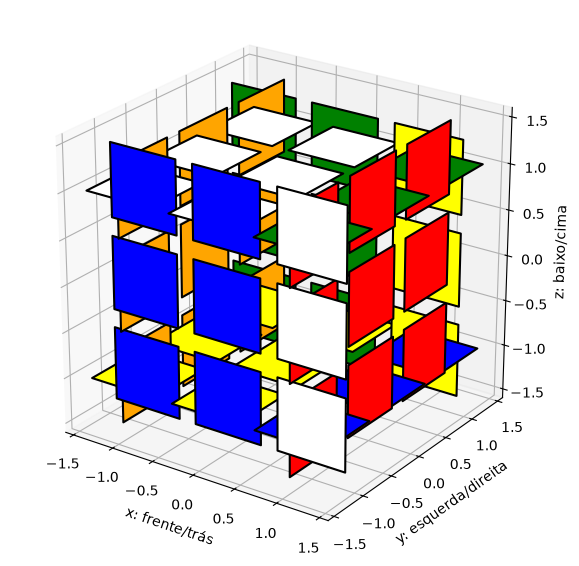

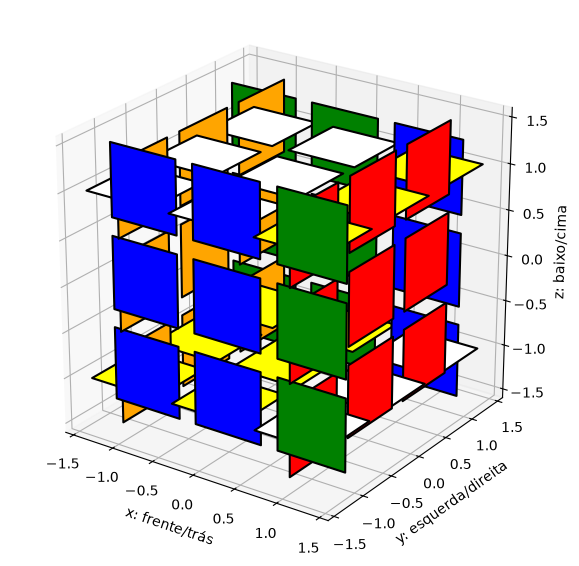

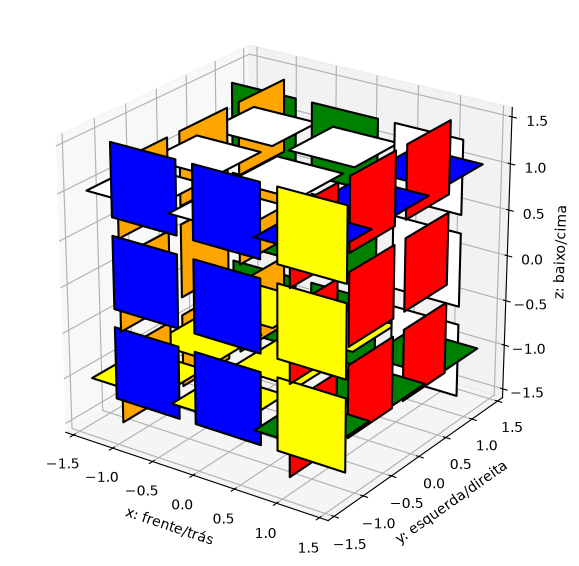

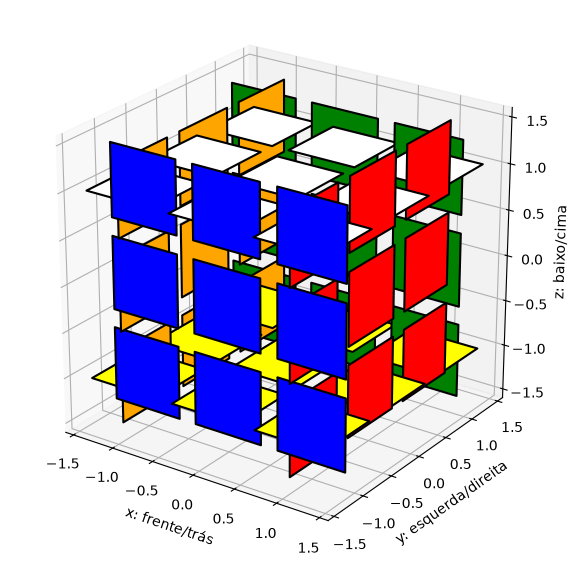

In [23]:
cubo_depois_de_F2 = girar_cubo(cubo_resolvido, mapa_F_geometrico)
plotar_cubo(cubo_depois_de_F2)
for i in range(0,3):
    cubo_depois_de_F2 = girar_cubo(cubo_depois_de_F2, mapa_F_geometrico)
    plotar_cubo(cubo_depois_de_F2)